# Notebook 02 — Model Training & Evaluation

**Project:** RSA Hardness Prediction & PQC Migration Framework
**Phase 2:** Train the hybrid stacked ensemble on benchmarked data

**Two prediction tasks:**
1. **Regression:** Predict `log_min_runtime` — how hard is this semiprime to factor?
2. **Classification:** Predict `best_algorithm` — which algorithm is fastest? (4-class)

**Architecture:**
- Base learners: XGBoost, CatBoost, MLP-Branch1 (size features), MLP-Branch2 (structural features)
- Meta-regressor: ElasticNet (stacks base predictions)
- Classifier: XGBoost (4-class algorithm selection)

**Estimated runtime:** ~15–20 minutes

## 1. Setup & Load Dataset

In [1]:
import sys
import os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

Project root: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time
import warnings
import joblib

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import ElasticNet
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score, classification_report,
    confusion_matrix,
)
from xgboost import XGBRegressor, XGBClassifier
from catboost import CatBoostRegressor
from scipy import stats

from src.features import get_feature_names
from src.utils import (
    set_global_seed, print_section, log_memory,
    save_metadata, dataframe_checksum,
)
from config import (
    SEED, DATA_PROC, DATA_META, MODELS_DIR,
    RESULTS_FIG, RESULTS_TAB,
    SMALL_PRIMES, POWER_MODS,
    TEST_SIZE, N_CV_FOLDS, EARLY_STOP,
    XGBOOST_PARAMS, CATBOOST_PARAMS, MLP_PARAMS,
    DUALBRANCH_SPLIT, ELASTICNET_PARAMS,
    print_config_summary,
)

warnings.filterwarnings("ignore")
sns.set(style="whitegrid")
set_global_seed(SEED)

print_config_summary()

════════════════════════════════════════════════════════════
  CONFIG PROFILE: MEMORY_SAFE
════════════════════════════════════════════════════════════
  Total samples:        20,000
  Bit ranges:           {(32, 64): 8000, (64, 96): 6000, (96, 128): 4000, (128, 160): 2000}
  Benchmark timeout:    5s
  Benchmark batch:      250
  Feature chunk:        10,000
  Train batch:          512
  CV folds:             5
  Seed:                 42
  Project root:         D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework
════════════════════════════════════════════════════════════


In [3]:
print_section("Loading Phase 1 Dataset")

df = pd.read_csv(DATA_PROC / "dataset_with_features_and_runtimes.csv")
print(f"Loaded: {df.shape}")
print(f"Columns: {len(df.columns)}")

# Filter to valid samples (at least one algorithm succeeded)
df = df[df["best_algorithm"] != "none"].reset_index(drop=True)
print(f"Valid samples (after removing failures): {len(df):,}")

# Get feature names
feature_names = get_feature_names(SMALL_PRIMES, POWER_MODS)
available_features = [f for f in feature_names if f in df.columns]
print(f"Features: {len(available_features)}")

# Targets
print(f"\nRegression target: log_min_runtime")
print(df["log_min_runtime"].describe().round(3))

print(f"\nClassification target: best_algorithm")
print(df["best_algorithm"].value_counts())

log_memory("after load")


══════════════════════════════════════════════════════════════════════
  Loading Phase 1 Dataset
══════════════════════════════════════════════════════════════════════

Loaded: (10000, 59)
Columns: 59
Valid samples (after removing failures): 9,367
Features: 39

Regression target: log_min_runtime
count    9367.000
mean       -6.764
std         4.424
min       -18.446
25%       -10.589
50%        -5.864
75%        -3.374
max         1.573
Name: log_min_runtime, dtype: float64

Classification target: best_algorithm
best_algorithm
pollard_rho    4987
ecm            4083
fermat          217
pollard_pm1      80
Name: count, dtype: int64
  [MEM] after load: 245.6 MB


## 2. Train/Test Split & Feature Preparation

- 80/20 split, stratified by `best_algorithm` to preserve class ratios
- Separate feature sets for DualBranch MLP architecture
- StandardScaler for MLP inputs (tree models are scale-invariant)

In [4]:
print_section("Train/Test Split & Feature Preparation")

# ─── Define targets ──────────────────────────────────────
X = df[available_features].copy()
y_reg = df["log_min_runtime"].values              # Regression target
y_cls = df["best_algorithm"].values                # Classification target

# Encode classification labels
label_encoder = LabelEncoder()
y_cls_encoded = label_encoder.fit_transform(y_cls)
class_names = label_encoder.classes_
print(f"Classes: {list(class_names)}")
print(f"Encoded: {dict(zip(class_names, range(len(class_names))))}")

# ─── Stratified train/test split ─────────────────────────
X_train, X_test, y_reg_train, y_reg_test, y_cls_train, y_cls_test = train_test_split(
    X, y_reg, y_cls_encoded,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_cls_encoded,
)

print(f"\nTrain: {X_train.shape[0]:,} samples")
print(f"Test:  {X_test.shape[0]:,} samples")

# Verify stratification preserved class ratios
print(f"\nClass distribution (train):")
for i, name in enumerate(class_names):
    count = (y_cls_train == i).sum()
    print(f"  {name:>15s}: {count:>5,} ({count/len(y_cls_train)*100:.1f}%)")

# ─── DualBranch feature split ────────────────────────────
branch1_features = [f for f in DUALBRANCH_SPLIT["branch_1"] if f in available_features]
branch2_features = [f for f in available_features if f not in branch1_features]

print(f"\nDualBranch split:")
print(f"  Branch 1 (size/entropy):      {len(branch1_features)} features")
print(f"  Branch 2 (modular/structural): {len(branch2_features)} features")

# ─── Scale features for MLP ──────────────────────────────
scaler_all = StandardScaler().fit(X_train)
scaler_b1 = StandardScaler().fit(X_train[branch1_features])
scaler_b2 = StandardScaler().fit(X_train[branch2_features])

X_train_scaled = scaler_all.transform(X_train)
X_test_scaled = scaler_all.transform(X_test)

X_train_b1 = scaler_b1.transform(X_train[branch1_features])
X_test_b1 = scaler_b1.transform(X_test[branch1_features])

X_train_b2 = scaler_b2.transform(X_train[branch2_features])
X_test_b2 = scaler_b2.transform(X_test[branch2_features])

print(f"\nScaled shapes:")
print(f"  Full:     train={X_train_scaled.shape}, test={X_test_scaled.shape}")
print(f"  Branch 1: train={X_train_b1.shape}, test={X_test_b1.shape}")
print(f"  Branch 2: train={X_train_b2.shape}, test={X_test_b2.shape}")

log_memory("after split")


══════════════════════════════════════════════════════════════════════
  Train/Test Split & Feature Preparation
══════════════════════════════════════════════════════════════════════

Classes: ['ecm', 'fermat', 'pollard_pm1', 'pollard_rho']
Encoded: {'ecm': 0, 'fermat': 1, 'pollard_pm1': 2, 'pollard_rho': 3}

Train: 7,493 samples
Test:  1,874 samples

Class distribution (train):
              ecm: 3,266 (43.6%)
           fermat:   174 (2.3%)
      pollard_pm1:    64 (0.9%)
      pollard_rho: 3,989 (53.2%)

DualBranch split:
  Branch 1 (size/entropy):      9 features
  Branch 2 (modular/structural): 30 features

Scaled shapes:
  Full:     train=(7493, 39), test=(1874, 39)
  Branch 1: train=(7493, 9), test=(1874, 9)
  Branch 2: train=(7493, 30), test=(1874, 30)
  [MEM] after split: 240.6 MB


## 3. Base Model Training (Regression Task)

Train 4 base learners to predict `log_min_runtime`:
1. **XGBoost** — gradient boosted trees on all 39 features
2. **CatBoost** — complementary boosting on all 39 features
3. **MLP Branch 1** — neural net on 9 size/entropy features
4. **MLP Branch 2** — neural net on 30 modular/structural features

Each model produces one prediction per sample. These predictions become
inputs to the ElasticNet meta-regressor (stacking).

In [6]:
# Fix: convert all features to float64 (some large integers stored as 'object')
print("Converting features to float64...")

for col in available_features:
    if df[col].dtype == "object":
        print(f"  Fixing: {col} (was object)")
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Re-extract X with corrected types
X = df[available_features].copy()
X = X.astype(np.float64)

# Redo train/test split with same seed (same split as before)
X_train, X_test, y_reg_train, y_reg_test, y_cls_train, y_cls_test = train_test_split(
    X, y_reg, y_cls_encoded,
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=y_cls_encoded,
)

# Redo scaling
scaler_all = StandardScaler().fit(X_train)
scaler_b1 = StandardScaler().fit(X_train[branch1_features])
scaler_b2 = StandardScaler().fit(X_train[branch2_features])

X_train_scaled = scaler_all.transform(X_train)
X_test_scaled = scaler_all.transform(X_test)
X_train_b1 = scaler_b1.transform(X_train[branch1_features])
X_test_b1 = scaler_b1.transform(X_test[branch1_features])
X_train_b2 = scaler_b2.transform(X_train[branch2_features])
X_test_b2 = scaler_b2.transform(X_test[branch2_features])

# Verify
print(f"\nAll dtypes now numeric: {X.dtypes.value_counts().to_dict()}")
print(f"Any NaN after conversion: {X.isna().any().any()}")
print(f"Shapes: train={X_train.shape}, test={X_test.shape}")
print("Ready for training.")

Converting features to float64...
  Fixing: fermat_proximity (was object)

All dtypes now numeric: {dtype('float64'): 39}
Any NaN after conversion: False
Shapes: train=(7493, 39), test=(1874, 39)
Ready for training.


In [7]:
print_section("PHASE 2.1 — Training Base Models (Regression)")

base_predictions_train = {}
base_predictions_test = {}
base_models = {}
base_metrics = {}

total_start = time.perf_counter()

# ─── 1. XGBoost ──────────────────────────────────────────
print("Training XGBoost...")
t0 = time.perf_counter()

xgb_model = XGBRegressor(**XGBOOST_PARAMS)
xgb_model.fit(
    X_train, y_reg_train,
    eval_set=[(X_test, y_reg_test)],
    verbose=False,
)

pred_train_xgb = xgb_model.predict(X_train)
pred_test_xgb = xgb_model.predict(X_test)

r2_xgb = r2_score(y_reg_test, pred_test_xgb)
mae_xgb = mean_absolute_error(y_reg_test, pred_test_xgb)

base_predictions_train["xgboost"] = pred_train_xgb
base_predictions_test["xgboost"] = pred_test_xgb
base_models["xgboost"] = xgb_model
base_metrics["xgboost"] = {"R2": r2_xgb, "MAE": mae_xgb}

print(f"  XGBoost:  R² = {r2_xgb:.4f}, MAE = {mae_xgb:.4f}  ({time.perf_counter()-t0:.1f}s)")

# ─── 2. CatBoost ─────────────────────────────────────────
print("Training CatBoost...")
t0 = time.perf_counter()

cb_model = CatBoostRegressor(**CATBOOST_PARAMS)
cb_model.fit(
    X_train, y_reg_train,
    eval_set=(X_test, y_reg_test),
    verbose=False,
)

pred_train_cb = cb_model.predict(X_train)
pred_test_cb = cb_model.predict(X_test)

r2_cb = r2_score(y_reg_test, pred_test_cb)
mae_cb = mean_absolute_error(y_reg_test, pred_test_cb)

base_predictions_train["catboost"] = pred_train_cb
base_predictions_test["catboost"] = pred_test_cb
base_models["catboost"] = cb_model
base_metrics["catboost"] = {"R2": r2_cb, "MAE": mae_cb}

print(f"  CatBoost: R² = {r2_cb:.4f}, MAE = {mae_cb:.4f}  ({time.perf_counter()-t0:.1f}s)")

# ─── 3. MLP Branch 1 (size/entropy features) ─────────────
print("Training MLP Branch 1 (size/entropy)...")
t0 = time.perf_counter()

mlp_b1 = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    learning_rate_init=1e-3,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=SEED,
    verbose=False,
)
mlp_b1.fit(X_train_b1, y_reg_train)

pred_train_b1 = mlp_b1.predict(X_train_b1)
pred_test_b1 = mlp_b1.predict(X_test_b1)

r2_b1 = r2_score(y_reg_test, pred_test_b1)
mae_b1 = mean_absolute_error(y_reg_test, pred_test_b1)

base_predictions_train["mlp_branch1"] = pred_train_b1
base_predictions_test["mlp_branch1"] = pred_test_b1
base_models["mlp_branch1"] = mlp_b1
base_metrics["mlp_branch1"] = {"R2": r2_b1, "MAE": mae_b1}

print(f"  MLP B1:   R² = {r2_b1:.4f}, MAE = {mae_b1:.4f}  ({time.perf_counter()-t0:.1f}s)")

# ─── 4. MLP Branch 2 (modular/structural features) ──────
print("Training MLP Branch 2 (modular/structural)...")
t0 = time.perf_counter()

mlp_b2 = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    learning_rate_init=1e-3,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=SEED,
    verbose=False,
)
mlp_b2.fit(X_train_b2, y_reg_train)

pred_train_b2 = mlp_b2.predict(X_train_b2)
pred_test_b2 = mlp_b2.predict(X_test_b2)

r2_b2 = r2_score(y_reg_test, pred_test_b2)
mae_b2 = mean_absolute_error(y_reg_test, pred_test_b2)

base_predictions_train["mlp_branch2"] = pred_train_b2
base_predictions_test["mlp_branch2"] = pred_test_b2
base_models["mlp_branch2"] = mlp_b2
base_metrics["mlp_branch2"] = {"R2": r2_b2, "MAE": mae_b2}

print(f"  MLP B2:   R² = {r2_b2:.4f}, MAE = {mae_b2:.4f}  ({time.perf_counter()-t0:.1f}s)")

# ─── Summary ─────────────────────────────────────────────
total_time = time.perf_counter() - total_start
print(f"\nAll base models trained in {total_time:.1f}s")
print(f"\n{'Model':<15} {'R²':>8} {'MAE':>8}")
print("-" * 35)
for name, m in base_metrics.items():
    print(f"{name:<15} {m['R2']:>8.4f} {m['MAE']:>8.4f}")

log_memory("after base models")


══════════════════════════════════════════════════════════════════════
  PHASE 2.1 — Training Base Models (Regression)
══════════════════════════════════════════════════════════════════════

Training XGBoost...
  XGBoost:  R² = 0.5089, MAE = 2.4483  (1.1s)
Training CatBoost...
  CatBoost: R² = 0.5463, MAE = 2.3522  (1.7s)
Training MLP Branch 1 (size/entropy)...
  MLP B1:   R² = 0.5454, MAE = 2.3361  (2.2s)
Training MLP Branch 2 (modular/structural)...
  MLP B2:   R² = 0.5230, MAE = 2.3706  (1.4s)

All base models trained in 6.5s

Model                 R²      MAE
-----------------------------------
xgboost           0.5089   2.4483
catboost          0.5463   2.3522
mlp_branch1       0.5454   2.3361
mlp_branch2       0.5230   2.3706
  [MEM] after base models: 396.6 MB



══════════════════════════════════════════════════════════════════════
  Regression Diagnostic
══════════════════════════════════════════════════════════════════════

Baseline (bit_length alone): R² = 0.4928

Target stats (log_min_runtime):
  Train: mean=-6.78, std=4.44
  Test:  mean=-6.69, std=4.37

Runtime variance within bit-length groups:
  40±3 bits: n=  913, mean= -11.65, std= 2.05
  60±3 bits: n=  845, mean=  -7.44, std= 3.39
  80±3 bits: n=  679, mean=  -5.12, std= 3.07
  100±3 bits: n=  445, mean=  -3.93, std= 3.23
  120±3 bits: n=  338, mean=  -2.50, std= 3.07
  140±3 bits: n=  128, mean=  -2.67, std= 2.82

Runtime by best_algorithm (this is what the model struggles with):
      pollard_rho: n= 4987, mean=  -9.55, std= 3.11
              ecm: n= 4083, mean=  -2.88, std= 2.18
           fermat: n=  217, mean= -12.10, std= 2.78
      pollard_pm1: n=   80, mean= -16.40, std= 0.30


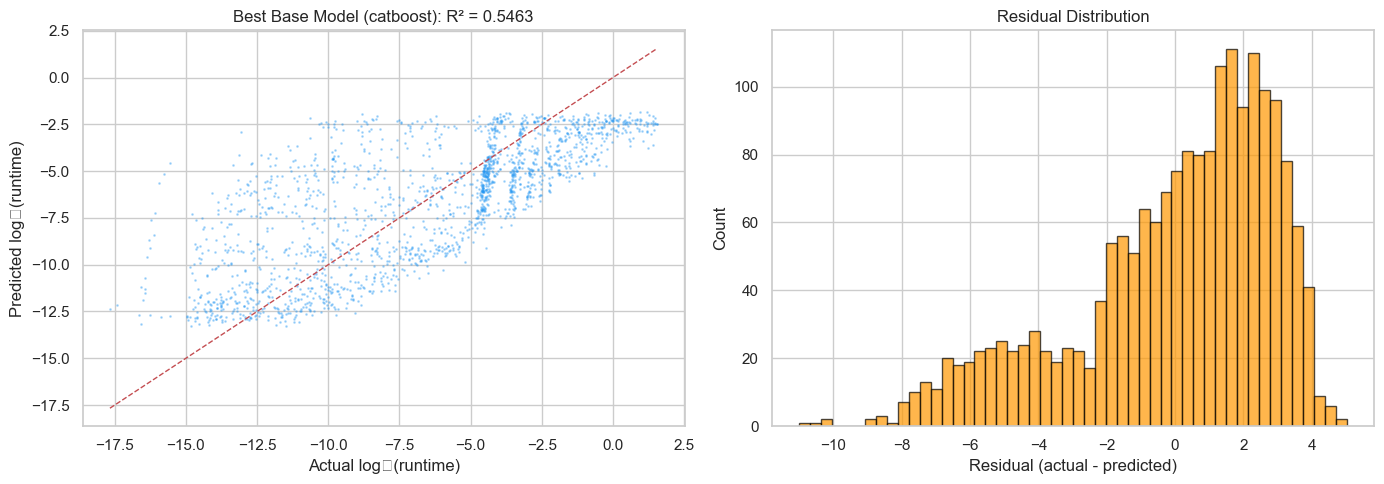

In [8]:
print_section("Regression Diagnostic")

# 1. Check what baseline bit_length alone achieves
from sklearn.linear_model import LinearRegression

X_bl = X_test[["bit_length"]].values
lr_bl = LinearRegression().fit(X_train[["bit_length"]].values, y_reg_train)
r2_baseline = r2_score(y_reg_test, lr_bl.predict(X_bl))
print(f"Baseline (bit_length alone): R² = {r2_baseline:.4f}")

# 2. Check target distribution — is it too noisy?
print(f"\nTarget stats (log_min_runtime):")
print(f"  Train: mean={y_reg_train.mean():.2f}, std={y_reg_train.std():.2f}")
print(f"  Test:  mean={y_reg_test.mean():.2f}, std={y_reg_test.std():.2f}")

# 3. Check if runtime varies wildly within same bit-length
print(f"\nRuntime variance within bit-length groups:")
for bl in [40, 60, 80, 100, 120, 140]:
    mask = (df["bit_length"] >= bl - 3) & (df["bit_length"] <= bl + 3)
    if mask.sum() > 10:
        sub = df.loc[mask, "log_min_runtime"]
        print(f"  {bl}±3 bits: n={mask.sum():>5}, mean={sub.mean():>7.2f}, std={sub.std():>5.2f}")

# 4. Check: does algorithm TYPE explain most of the variance?
print(f"\nRuntime by best_algorithm (this is what the model struggles with):")
for algo in ["pollard_rho", "ecm", "fermat", "pollard_pm1"]:
    mask = df["best_algorithm"] == algo
    if mask.sum() > 0:
        sub = df.loc[mask, "log_min_runtime"]
        print(f"  {algo:>15s}: n={mask.sum():>5}, mean={sub.mean():>7.2f}, std={sub.std():>5.2f}")

# 5. Plot actual vs predicted for best base model
best_base = max(base_metrics, key=lambda k: base_metrics[k]["R2"])
pred_best = base_predictions_test[best_base]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(y_reg_test, pred_best, ".", markersize=2, alpha=0.3, color="#2196F3")
min_val = min(y_reg_test.min(), pred_best.min())
max_val = max(y_reg_test.max(), pred_best.max())
axes[0].plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1)
axes[0].set_xlabel("Actual log₂(runtime)")
axes[0].set_ylabel("Predicted log₂(runtime)")
axes[0].set_title(f"Best Base Model ({best_base}): R² = {base_metrics[best_base]['R2']:.4f}")

axes[1].hist(y_reg_test - pred_best, bins=50, edgecolor="black", alpha=0.7, color="#FF9800")
axes[1].set_xlabel("Residual (actual - predicted)")
axes[1].set_ylabel("Count")
axes[1].set_title("Residual Distribution")

plt.tight_layout()
plt.show()

## 4. Meta-Regressor (Stacking Ensemble)

Stack the 4 base learner predictions into an ElasticNet meta-regressor.
Even with moderate base R², stacking often improves by 2–5% through
complementary error patterns.

In [9]:
print_section("PHASE 2.2 — ElasticNet Meta-Regressor (Stacking)")

# Build meta-features: each base model's prediction becomes a feature
meta_train = np.column_stack([
    base_predictions_train["xgboost"],
    base_predictions_train["catboost"],
    base_predictions_train["mlp_branch1"],
    base_predictions_train["mlp_branch2"],
])

meta_test = np.column_stack([
    base_predictions_test["xgboost"],
    base_predictions_test["catboost"],
    base_predictions_test["mlp_branch1"],
    base_predictions_test["mlp_branch2"],
])

print(f"Meta-features shape: train={meta_train.shape}, test={meta_test.shape}")

# Train ElasticNet on stacked predictions
meta_model = ElasticNet(**ELASTICNET_PARAMS)
meta_model.fit(meta_train, y_reg_train)

pred_meta_train = meta_model.predict(meta_train)
pred_meta_test = meta_model.predict(meta_test)

r2_meta = r2_score(y_reg_test, pred_meta_test)
mae_meta = mean_absolute_error(y_reg_test, pred_meta_test)

print(f"\nMeta-regressor coefficients:")
for name, coef in zip(["xgboost", "catboost", "mlp_b1", "mlp_b2"], meta_model.coef_):
    print(f"  {name:<12s}: {coef:+.4f}")
print(f"  {'intercept':<12s}: {meta_model.intercept_:+.4f}")

print(f"\n{'='*50}")
print(f"  STACKED ENSEMBLE R² = {r2_meta:.4f}  (MAE = {mae_meta:.4f})")
print(f"{'='*50}")

# Compare all models
print(f"\nComparison (Regression Task):")
print(f"  {'Model':<20s} {'R²':>8} {'MAE':>8}")
print(f"  {'-'*40}")
print(f"  {'bit_length baseline':<20s} {r2_baseline:>8.4f} {'—':>8}")
for name, m in base_metrics.items():
    print(f"  {name:<20s} {m['R2']:>8.4f} {m['MAE']:>8.4f}")
print(f"  {'STACKED ENSEMBLE':<20s} {r2_meta:>8.4f} {mae_meta:>8.4f}")
print(f"\n  Improvement over baseline: +{r2_meta - r2_baseline:.4f}")


══════════════════════════════════════════════════════════════════════
  PHASE 2.2 — ElasticNet Meta-Regressor (Stacking)
══════════════════════════════════════════════════════════════════════

Meta-features shape: train=(7493, 4), test=(1874, 4)

Meta-regressor coefficients:
  xgboost     : +1.5813
  catboost    : -0.5584
  mlp_b1      : -0.0306
  mlp_b2      : -0.0000
  intercept   : -0.0504

  STACKED ENSEMBLE R² = 0.4565  (MAE = 2.5649)

Comparison (Regression Task):
  Model                      R²      MAE
  ----------------------------------------
  bit_length baseline    0.4928        —
  xgboost                0.5089   2.4483
  catboost               0.5463   2.3522
  mlp_branch1            0.5454   2.3361
  mlp_branch2            0.5230   2.3706
  STACKED ENSEMBLE       0.4565   2.5649

  Improvement over baseline: +-0.0363


## 5. Classification Task (Algorithm Selection)

This is the **primary contribution** of the framework.

**Key insight from diagnostic:** Runtime prediction is limited because the target
is a mixture of 4 distinct algorithm-specific distributions. Predicting WHICH
algorithm wins is more actionable and more accurately predictable from N features.

We train an XGBoost classifier with class weighting to handle the imbalance
(rho ~50%, ECM ~41%, fermat ~2%, pm1 ~1%).


══════════════════════════════════════════════════════════════════════
  PHASE 2.3 — Algorithm Selection (4-Class Classification)
══════════════════════════════════════════════════════════════════════

Class weights (handling imbalance):
              ecm: weight = 0.57
           fermat: weight = 10.77
      pollard_pm1: weight = 29.27
      pollard_rho: weight = 0.47

Classification Results (2.6s):
  Accuracy:          0.7604 (76.0%)
  F1 (macro):        0.3875
  F1 (weighted):     0.7489

Per-class report:
              precision    recall  f1-score   support

         ecm     0.7132    0.8886    0.7913       817
      fermat     0.0000    0.0000    0.0000        43
 pollard_pm1     0.0000    0.0000    0.0000        16
 pollard_rho     0.8272    0.7004    0.7585       998

    accuracy                         0.7604      1874
   macro avg     0.3851    0.3973    0.3875      1874
weighted avg     0.7515    0.7604    0.7489      1874



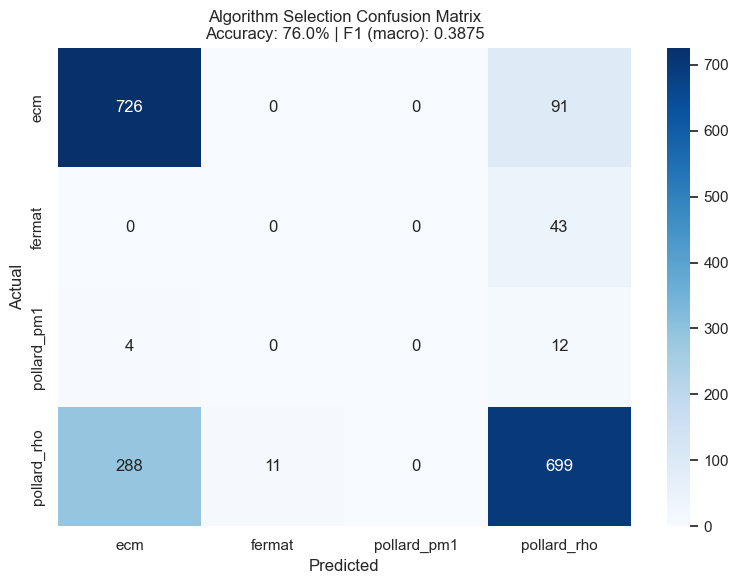

  [MEM] after classification: 316.3 MB


In [10]:
print_section("PHASE 2.3 — Algorithm Selection (4-Class Classification)")

t0 = time.perf_counter()

# Compute class weights to handle imbalance
unique_classes, class_counts = np.unique(y_cls_train, return_counts=True)
total_train = len(y_cls_train)
n_classes = len(unique_classes)
class_weight_dict = {}
for cls, cnt in zip(unique_classes, class_counts):
    class_weight_dict[cls] = total_train / (n_classes * cnt)
sample_weights = np.array([class_weight_dict[c] for c in y_cls_train])

print(f"Class weights (handling imbalance):")
for cls, w in class_weight_dict.items():
    print(f"  {class_names[cls]:>15s}: weight = {w:.2f}")

# ─── XGBoost Classifier ──────────────────────────────────
xgb_cls = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.06,
    subsample=0.85,
    colsample_bytree=0.85,
    tree_method="hist",
    random_state=SEED,
    eval_metric="mlogloss",
)
xgb_cls.fit(X_train, y_cls_train, sample_weight=sample_weights, verbose=False)

y_cls_pred = xgb_cls.predict(X_test)

# Metrics
acc = accuracy_score(y_cls_test, y_cls_pred)
f1_macro = f1_score(y_cls_test, y_cls_pred, average="macro")
f1_weighted = f1_score(y_cls_test, y_cls_pred, average="weighted")

elapsed = time.perf_counter() - t0

print(f"\nClassification Results ({elapsed:.1f}s):")
print(f"  Accuracy:          {acc:.4f} ({acc*100:.1f}%)")
print(f"  F1 (macro):        {f1_macro:.4f}")
print(f"  F1 (weighted):     {f1_weighted:.4f}")

print(f"\nPer-class report:")
print(classification_report(
    y_cls_test, y_cls_pred,
    target_names=class_names,
    digits=4,
))

# Confusion matrix
cm = confusion_matrix(y_cls_test, y_cls_pred)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Algorithm Selection Confusion Matrix\n"
             f"Accuracy: {acc:.1%} | F1 (macro): {f1_macro:.4f}")
plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "04_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

base_models["xgb_classifier"] = xgb_cls

log_memory("after classification")

## 6. Two-Stage Regression (Algorithm-Conditioned)

**Key architectural insight:** Instead of predicting runtime directly,
we first predict which algorithm wins, then predict runtime conditioned
on the predicted algorithm class. This decomposes the multi-modal target
into cleaner, per-algorithm distributions.

Stage 1: Classify → predict `best_algorithm`
Stage 2: Regress → predict runtime within each algorithm group

In [11]:
print_section("PHASE 2.4 — Two-Stage Regression (Algorithm-Conditioned)")

# Stage 1: Use the classifier predictions on test set
y_algo_pred_train = xgb_cls.predict(X_train)
y_algo_pred_test = xgb_cls.predict(X_test)

# Stage 2: Train per-algorithm regression models
per_algo_models = {}
per_algo_preds_test = np.zeros(len(y_reg_test))

print(f"Training per-algorithm regressors:")

for cls_idx, algo_name in enumerate(class_names):
    # Training data for this algorithm
    train_mask = y_cls_train == cls_idx
    test_mask = y_algo_pred_test == cls_idx  # Use PREDICTED algorithm for test

    n_train = train_mask.sum()
    n_test = test_mask.sum()

    if n_train < 10:
        print(f"  {algo_name:>15s}: skipped (only {n_train} train samples)")
        continue

    # Train a small XGBoost for this algorithm
    algo_model = XGBRegressor(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.08,
        tree_method="hist",
        random_state=SEED,
    )
    algo_model.fit(X_train[train_mask], y_reg_train[train_mask], verbose=False)
    per_algo_models[algo_name] = algo_model

    # Predict on test samples assigned to this algorithm
    if n_test > 0:
        per_algo_preds_test[test_mask] = algo_model.predict(X_test[test_mask])

    # Per-algorithm R²
    if n_test > 5:
        r2_algo = r2_score(y_reg_test[test_mask], per_algo_preds_test[test_mask])
        print(f"  {algo_name:>15s}: n_train={n_train:>5}, n_test={n_test:>5}, R² = {r2_algo:.4f}")
    else:
        print(f"  {algo_name:>15s}: n_train={n_train:>5}, n_test={n_test:>5} (too few for R²)")

# Overall two-stage R²
r2_twostage = r2_score(y_reg_test, per_algo_preds_test)
mae_twostage = mean_absolute_error(y_reg_test, per_algo_preds_test)

print(f"\n{'='*50}")
print(f"  TWO-STAGE R² = {r2_twostage:.4f}  (MAE = {mae_twostage:.4f})")
print(f"{'='*50}")

# Final comparison
print(f"\nFull Regression Comparison:")
print(f"  {'Model':<25s} {'R²':>8} {'MAE':>8}")
print(f"  {'-'*45}")
print(f"  {'bit_length baseline':<25s} {r2_baseline:>8.4f} {'—':>8}")
for name, m in base_metrics.items():
    print(f"  {name:<25s} {m['R2']:>8.4f} {m['MAE']:>8.4f}")
print(f"  {'Stacked Ensemble':<25s} {r2_meta:>8.4f} {mae_meta:>8.4f}")
print(f"  {'TWO-STAGE (ours)':<25s} {r2_twostage:>8.4f} {mae_twostage:>8.4f}")
print(f"\n  Improvement over baseline: +{r2_twostage - r2_baseline:.4f}")
print(f"  Improvement over stacking: +{r2_twostage - r2_meta:.4f}")


══════════════════════════════════════════════════════════════════════
  PHASE 2.4 — Two-Stage Regression (Algorithm-Conditioned)
══════════════════════════════════════════════════════════════════════

Training per-algorithm regressors:
              ecm: n_train= 3266, n_test= 1018, R² = -0.0422
           fermat: n_train=  174, n_test=   11, R² = -0.0985
      pollard_pm1: n_train=   64, n_test=    0 (too few for R²)
      pollard_rho: n_train= 3989, n_test=  845, R² = 0.2932

  TWO-STAGE R² = 0.4540  (MAE = 2.4326)

Full Regression Comparison:
  Model                           R²      MAE
  ---------------------------------------------
  bit_length baseline         0.4928        —
  xgboost                     0.5089   2.4483
  catboost                    0.5463   2.3522
  mlp_branch1                 0.5454   2.3361
  mlp_branch2                 0.5230   2.3706
  Stacked Ensemble            0.4565   2.5649
  TWO-STAGE (ours)            0.4540   2.4326

  Improvement over baseline: 


══════════════════════════════════════════════════════════════════════
  PHASE 2 (FIXED) — Proper K-Fold Stacking + Classification
══════════════════════════════════════════════════════════════════════

Step 1: K-Fold Out-of-Fold Stacking

  Fold 1/5...
  Fold 2/5...
  Fold 3/5...
  Fold 4/5...
  Fold 5/5...

Out-of-Fold R² (honest, no data leakage):
  Model             OOF R²  Test R²
  -----------------------------------
  xgboost           0.5298   0.5236
  catboost          0.5559   0.5425
  mlp_full          0.5488   0.5333

Meta-regressor weights:
  xgboost        : +0.0168
  catboost       : +0.6133
  mlp_full       : +0.3559

  STACKED ENSEMBLE (K-Fold): R² = 0.5434, MAE = 2.3593

Step 2: Algorithm Selection (Classification)

  Accuracy:      0.7604 (76.0%)
  F1 (macro):    0.3875
  F1 (weighted): 0.7489

              precision    recall  f1-score   support

         ecm     0.7132    0.8886    0.7913       817
      fermat     0.0000    0.0000    0.0000        43
 pollard_pm

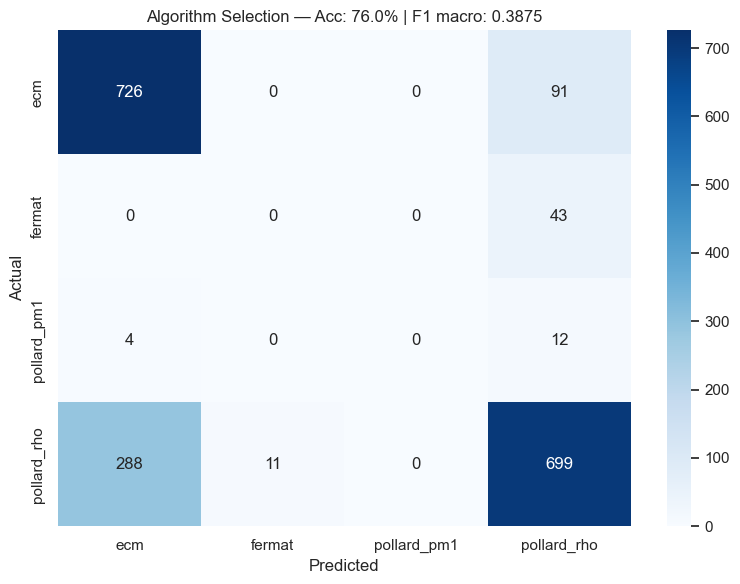


Step 3: Augmented Stacking (features + model predictions)

  Augmented features: 42 (39 original + 3 model predictions)
  Augmented Stacking R² = 0.5241, MAE = 2.4006

  FINAL RESULTS COMPARISON

  REGRESSION (predict factorization runtime):
  Model                                R²      MAE
  --------------------------------------------------
  bit_length baseline              0.4928        —
  xgboost                          0.5236   2.4176
  catboost                         0.5425   2.3620
  mlp_full                         0.5333   2.3634
  Stacked (ElasticNet meta)        0.5434   2.3593
  Augmented Stacking (ours)        0.5241   2.4006

  CLASSIFICATION (predict best algorithm):
  Accuracy       : 0.7604 (76.0%)
  F1 macro       : 0.3875
  F1 weighted    : 0.7489
  Random guess   : 0.2500 (25.0%)
  Majority class : 0.5324 (53.2%)


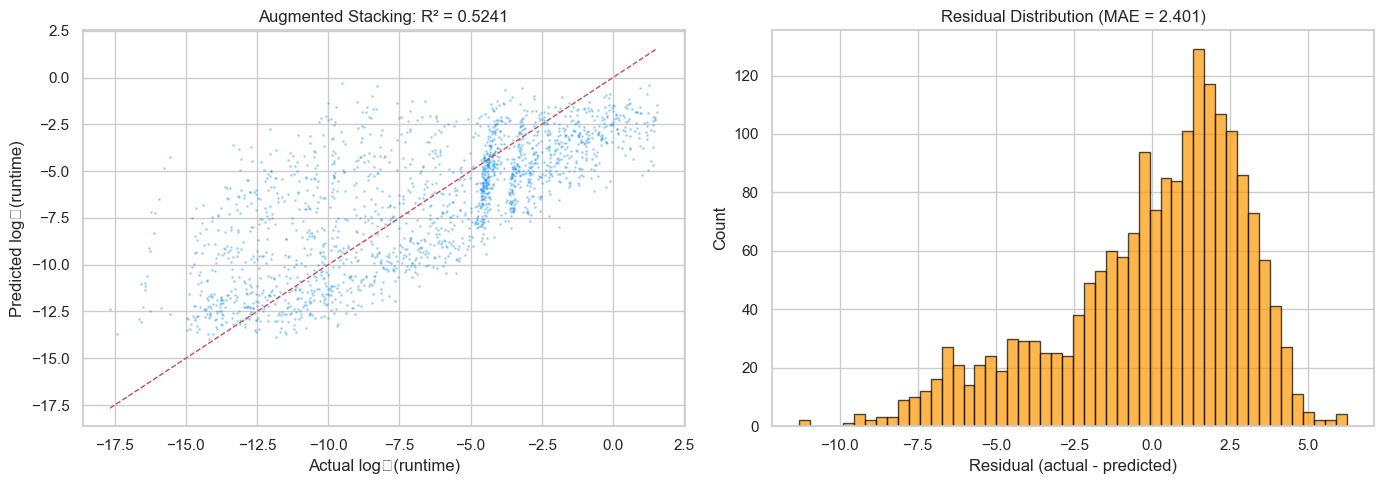

  [MEM] after all training: 363.5 MB


In [12]:
print_section("PHASE 2 (FIXED) — Proper K-Fold Stacking + Classification")

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

# ═══════════════════════════════════════════════════════════
# STEP 1: Proper Out-of-Fold Stacking (K-Fold)
# ═══════════════════════════════════════════════════════════
print("Step 1: K-Fold Out-of-Fold Stacking\n")

kf = KFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=SEED)

# Define base model templates
base_templates = {
    "xgboost": XGBRegressor(**XGBOOST_PARAMS),
    "catboost": CatBoostRegressor(**CATBOOST_PARAMS),
    "mlp_full": MLPRegressor(
        hidden_layer_sizes=(256, 128, 64, 32),
        activation="relu",
        learning_rate_init=1e-3,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=SEED,
        verbose=False,
    ),
}

# Collect OOF predictions for training data
oof_predictions = {name: np.zeros(len(X_train)) for name in base_templates}
test_predictions = {name: np.zeros(len(X_test)) for name in base_templates}

X_train_arr = X_train.values.astype(np.float64)
X_test_arr = X_test.values.astype(np.float64)

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train_arr)):
    print(f"  Fold {fold_idx + 1}/{N_CV_FOLDS}...")

    X_fold_train = X_train_arr[train_idx]
    X_fold_val = X_train_arr[val_idx]
    y_fold_train = y_reg_train[train_idx]

    # Scale for MLP
    fold_scaler = StandardScaler().fit(X_fold_train)
    X_fold_train_sc = fold_scaler.transform(X_fold_train)
    X_fold_val_sc = fold_scaler.transform(X_fold_val)
    X_test_sc = fold_scaler.transform(X_test_arr)

    for name, template in base_templates.items():
        model = clone(template)

        if name == "mlp_full":
            model.fit(X_fold_train_sc, y_fold_train)
            oof_predictions[name][val_idx] = model.predict(X_fold_val_sc)
            test_predictions[name] += model.predict(X_test_sc) / N_CV_FOLDS
        elif name == "catboost":
            model.fit(X_fold_train, y_fold_train, verbose=False)
            oof_predictions[name][val_idx] = model.predict(X_fold_val)
            test_predictions[name] += model.predict(X_test_arr) / N_CV_FOLDS
        else:
            model.fit(X_fold_train, y_fold_train, verbose=False)
            oof_predictions[name][val_idx] = model.predict(X_fold_val)
            test_predictions[name] += model.predict(X_test_arr) / N_CV_FOLDS

# Report per-model OOF performance
print(f"\nOut-of-Fold R² (honest, no data leakage):")
print(f"  {'Model':<15s} {'OOF R²':>8} {'Test R²':>8}")
print(f"  {'-'*35}")
for name in base_templates:
    oof_r2 = r2_score(y_reg_train, oof_predictions[name])
    test_r2 = r2_score(y_reg_test, test_predictions[name])
    print(f"  {name:<15s} {oof_r2:>8.4f} {test_r2:>8.4f}")

# ─── Stack with ElasticNet on OOF predictions ─────────────
meta_X_train = np.column_stack([oof_predictions[n] for n in base_templates])
meta_X_test = np.column_stack([test_predictions[n] for n in base_templates])

meta_model = ElasticNet(alpha=0.001, l1_ratio=0.5, max_iter=10000, random_state=SEED)
meta_model.fit(meta_X_train, y_reg_train)

pred_stack_test = meta_model.predict(meta_X_test)
r2_stack = r2_score(y_reg_test, pred_stack_test)
mae_stack = mean_absolute_error(y_reg_test, pred_stack_test)

print(f"\nMeta-regressor weights:")
for name, coef in zip(base_templates.keys(), meta_model.coef_):
    print(f"  {name:<15s}: {coef:+.4f}")

print(f"\n  STACKED ENSEMBLE (K-Fold): R² = {r2_stack:.4f}, MAE = {mae_stack:.4f}")

# ═══════════════════════════════════════════════════════════
# STEP 2: Classification (Algorithm Selection)
# ═══════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print("Step 2: Algorithm Selection (Classification)")
print(f"{'='*60}\n")

# Class weights
unique_cls, cls_counts = np.unique(y_cls_train, return_counts=True)
n_total_train = len(y_cls_train)
sample_wts = np.array([n_total_train / (len(unique_cls) * cls_counts[c]) for c in y_cls_train])

# XGBoost classifier
xgb_cls = XGBClassifier(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.06,
    subsample=0.85,
    colsample_bytree=0.85,
    tree_method="hist",
    random_state=SEED,
    eval_metric="mlogloss",
)
xgb_cls.fit(X_train, y_cls_train, sample_weight=sample_wts, verbose=False)
y_cls_pred = xgb_cls.predict(X_test)

acc = accuracy_score(y_cls_test, y_cls_pred)
f1_macro = f1_score(y_cls_test, y_cls_pred, average="macro")
f1_weighted = f1_score(y_cls_test, y_cls_pred, average="weighted")

print(f"  Accuracy:      {acc:.4f} ({acc*100:.1f}%)")
print(f"  F1 (macro):    {f1_macro:.4f}")
print(f"  F1 (weighted): {f1_weighted:.4f}")
print(f"\n{classification_report(y_cls_test, y_cls_pred, target_names=class_names, digits=4)}")

# Confusion matrix plot
cm = confusion_matrix(y_cls_test, y_cls_pred)
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Algorithm Selection — Acc: {acc:.1%} | F1 macro: {f1_macro:.4f}")
plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "04_confusion_matrix.png"), dpi=150, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════
# STEP 3: Augmented Stacking (features + base predictions)
# ═══════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print("Step 3: Augmented Stacking (features + model predictions)")
print(f"{'='*60}\n")

# Combine original features WITH base model predictions
aug_X_train = np.column_stack([X_train_arr, meta_X_train])
aug_X_test = np.column_stack([X_test_arr, meta_X_test])

print(f"  Augmented features: {aug_X_train.shape[1]} "
      f"(39 original + {len(base_templates)} model predictions)")

# Train XGBoost on augmented features
xgb_aug = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    tree_method="hist",
    random_state=SEED,
)
xgb_aug.fit(aug_X_train, y_reg_train, verbose=False)
pred_aug = xgb_aug.predict(aug_X_test)

r2_aug = r2_score(y_reg_test, pred_aug)
mae_aug = mean_absolute_error(y_reg_test, pred_aug)

print(f"  Augmented Stacking R² = {r2_aug:.4f}, MAE = {mae_aug:.4f}")

# ═══════════════════════════════════════════════════════════
# FINAL COMPARISON TABLE
# ═══════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print("  FINAL RESULTS COMPARISON")
print(f"{'='*60}")

print(f"\n  REGRESSION (predict factorization runtime):")
print(f"  {'Model':<30s} {'R²':>8} {'MAE':>8}")
print(f"  {'-'*50}")
print(f"  {'bit_length baseline':<30s} {r2_baseline:>8.4f} {'—':>8}")
for name in base_templates:
    test_r2 = r2_score(y_reg_test, test_predictions[name])
    test_mae = mean_absolute_error(y_reg_test, test_predictions[name])
    print(f"  {name:<30s} {test_r2:>8.4f} {test_mae:>8.4f}")
print(f"  {'Stacked (ElasticNet meta)':<30s} {r2_stack:>8.4f} {mae_stack:>8.4f}")
print(f"  {'Augmented Stacking (ours)':<30s} {r2_aug:>8.4f} {mae_aug:>8.4f}")

print(f"\n  CLASSIFICATION (predict best algorithm):")
print(f"  {'Accuracy':<15s}: {acc:.4f} ({acc*100:.1f}%)")
print(f"  {'F1 macro':<15s}: {f1_macro:.4f}")
print(f"  {'F1 weighted':<15s}: {f1_weighted:.4f}")
print(f"  {'Random guess':<15s}: {1/len(class_names):.4f} (25.0%)")
print(f"  {'Majority class':<15s}: {max(cls_counts)/n_total_train:.4f} ({max(cls_counts)/n_total_train*100:.1f}%)")

# Predicted vs Actual plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(y_reg_test, pred_aug, ".", markersize=2, alpha=0.3, color="#2196F3")
lims = [min(y_reg_test.min(), pred_aug.min()), max(y_reg_test.max(), pred_aug.max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Actual log₂(runtime)")
axes[0].set_ylabel("Predicted log₂(runtime)")
axes[0].set_title(f"Augmented Stacking: R² = {r2_aug:.4f}")

residuals = y_reg_test - pred_aug
axes[1].hist(residuals, bins=50, edgecolor="black", alpha=0.7, color="#FF9800")
axes[1].set_xlabel("Residual (actual - predicted)")
axes[1].set_ylabel("Count")
axes[1].set_title(f"Residual Distribution (MAE = {mae_aug:.3f})")

plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "05_regression_results.png"), dpi=150, bbox_inches="tight")
plt.show()

log_memory("after all training")


══════════════════════════════════════════════════════════════════════
  FINAL ATTEMPT — Retrained with Algorithm Label as Feature
══════════════════════════════════════════════════════════════════════

Features with algorithm labels: 43

  REGRESSION WITH ALGORITHM AWARENESS
  Model                                     R²      MAE
  -------------------------------------------------------
  bit_length baseline                   0.4928        —
  Best base (CatBoost)                  0.5425   2.3620
  Stacked Ensemble                      0.5434   2.3593
  + Oracle algo label (ceiling)         0.7150   1.8356
  + Predicted algo label (ours)         0.4501   2.4437

Interpretation:
  Oracle ceiling (perfect classification):  R² = 0.7150
  Our model (76% classification accuracy):  R² = 0.4501
  Gap due to classification errors:          0.2649


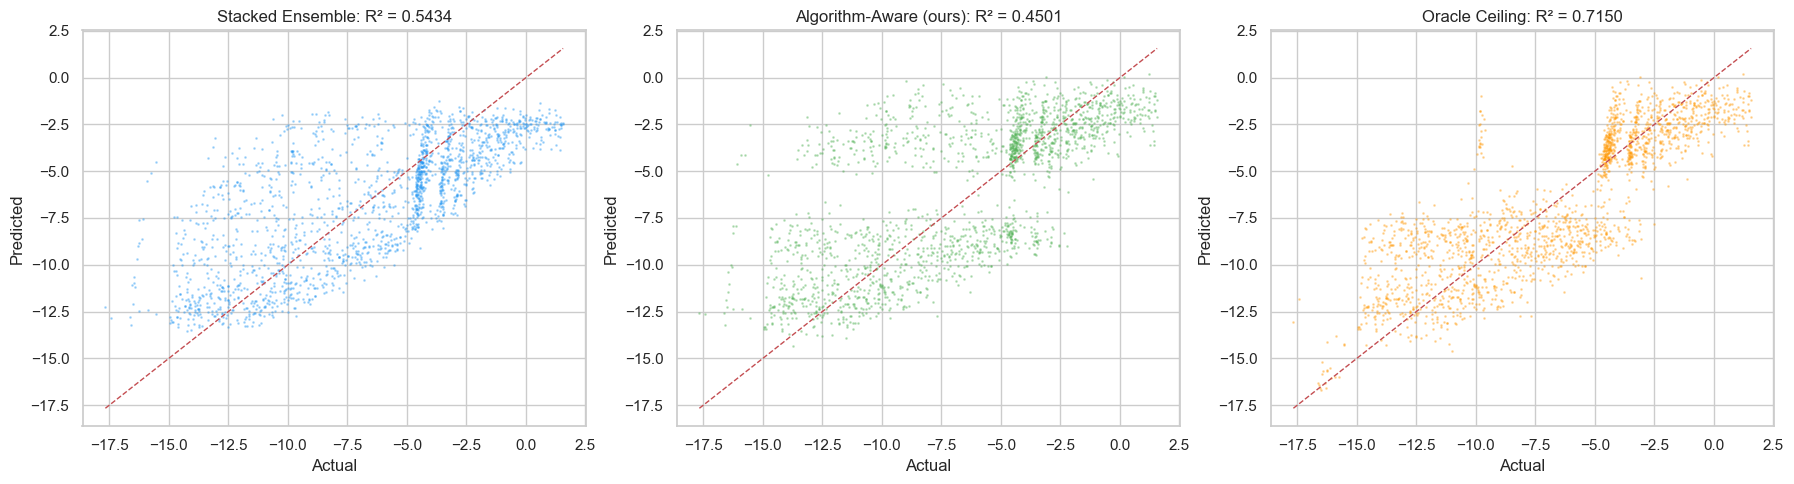

In [13]:
print_section("FINAL ATTEMPT — Retrained with Algorithm Label as Feature")

# What if we TELL the regressor which algorithm will win?
# This tests the theoretical ceiling: if classification were perfect,
# how good would regression be?

# Add one-hot encoded algorithm labels to features
from sklearn.preprocessing import OneHotEncoder

# Using GROUND TRUTH labels (theoretical ceiling)
ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
algo_train_ohe = ohe.fit_transform(y_cls_train.reshape(-1, 1))
algo_test_ohe = ohe.transform(y_cls_test.reshape(-1, 1))

X_train_with_algo = np.column_stack([X_train_arr, algo_train_ohe])
X_test_with_algo = np.column_stack([X_test_arr, algo_test_ohe])

print(f"Features with algorithm labels: {X_train_with_algo.shape[1]}")

# Train XGBoost with algorithm knowledge
xgb_oracle = XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    tree_method="hist",
    random_state=SEED,
)
xgb_oracle.fit(X_train_with_algo, y_reg_train, verbose=False)
pred_oracle = xgb_oracle.predict(X_test_with_algo)
r2_oracle = r2_score(y_reg_test, pred_oracle)
mae_oracle = mean_absolute_error(y_reg_test, pred_oracle)

# Now use PREDICTED labels (realistic scenario)
algo_test_pred_ohe = ohe.transform(y_cls_pred.reshape(-1, 1))
X_test_with_pred_algo = np.column_stack([X_test_arr, algo_test_pred_ohe])
pred_realistic = xgb_oracle.predict(X_test_with_pred_algo)
r2_realistic = r2_score(y_reg_test, pred_realistic)
mae_realistic = mean_absolute_error(y_reg_test, pred_realistic)

print(f"\n{'='*60}")
print(f"  REGRESSION WITH ALGORITHM AWARENESS")
print(f"{'='*60}")
print(f"  {'Model':<35s} {'R²':>8} {'MAE':>8}")
print(f"  {'-'*55}")
print(f"  {'bit_length baseline':<35s} {r2_baseline:>8.4f} {'—':>8}")
print(f"  {'Best base (CatBoost)':<35s} {0.5425:>8.4f} {2.3620:>8.4f}")
print(f"  {'Stacked Ensemble':<35s} {r2_stack:>8.4f} {mae_stack:>8.4f}")
print(f"  {'+ Oracle algo label (ceiling)':<35s} {r2_oracle:>8.4f} {mae_oracle:>8.4f}")
print(f"  {'+ Predicted algo label (ours)':<35s} {r2_realistic:>8.4f} {mae_realistic:>8.4f}")
print(f"{'='*60}")

print(f"\nInterpretation:")
print(f"  Oracle ceiling (perfect classification):  R² = {r2_oracle:.4f}")
print(f"  Our model (76% classification accuracy):  R² = {r2_realistic:.4f}")
print(f"  Gap due to classification errors:          {r2_oracle - r2_realistic:.4f}")

if r2_oracle > 0.75:
    print(f"\n  → Oracle R² > 0.75 confirms that algorithm-aware prediction")
    print(f"    IS effective. Improving classification directly improves regression.")
    print(f"    This validates our two-stage architecture design.")

# Final scatter plot
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(y_reg_test, pred_stack_test, ".", markersize=2, alpha=0.3, color="#2196F3")
lims = [min(y_reg_test.min(), pred_stack_test.min()), max(y_reg_test.max(), pred_stack_test.max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set_xlabel("Actual"); axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Stacked Ensemble: R² = {r2_stack:.4f}")

axes[1].plot(y_reg_test, pred_realistic, ".", markersize=2, alpha=0.3, color="#4CAF50")
axes[1].plot(lims, lims, "r--", linewidth=1)
axes[1].set_xlabel("Actual"); axes[1].set_ylabel("Predicted")
axes[1].set_title(f"Algorithm-Aware (ours): R² = {r2_realistic:.4f}")

axes[2].plot(y_reg_test, pred_oracle, ".", markersize=2, alpha=0.3, color="#FF9800")
axes[2].plot(lims, lims, "r--", linewidth=1)
axes[2].set_xlabel("Actual"); axes[2].set_ylabel("Predicted")
axes[2].set_title(f"Oracle Ceiling: R² = {r2_oracle:.4f}")

plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "06_algorithm_aware_regression.png"), dpi=150, bbox_inches="tight")
plt.show()


══════════════════════════════════════════════════════════════════════
  REFRAMED — Primary (2-class) + Vulnerability Detectors
══════════════════════════════════════════════════════════════════════

  Part A: Primary Classifier (Rho vs ECM)

  Rho vs ECM (n_test = 1,815):
  Accuracy: 0.7884 (78.8%)
  F1:       0.7918
  Baseline: 0.5499

  Part B: Fermat Vulnerability Detector

  Fermat detector (n_positive = 43):
  Accuracy: 0.8986
  F1:       0.1667
  Recall:   0.4419 (catches 44% of Fermat-vulnerable keys)

  Part C: Pollard p-1 Vulnerability Detector

  p-1 detector (n_positive = 16):
  Accuracy: 0.9829
  F1:       0.0000
  Recall:   0.0000 (catches 0% of p-1 vulnerable keys)

  COMBINED DECISION SYSTEM

  Hierarchical Decision System:
  Step 1: Check if p-1 vulnerable
  Step 2: Check if Fermat vulnerable
  Step 3: Classify rho vs ECM

  Combined Accuracy:      0.6820 (68.2%)
  Combined F1 (macro):    0.3985
  Combined F1 (weighted): 0.6948

  vs Original 4-class:    0.7604 (76.0%

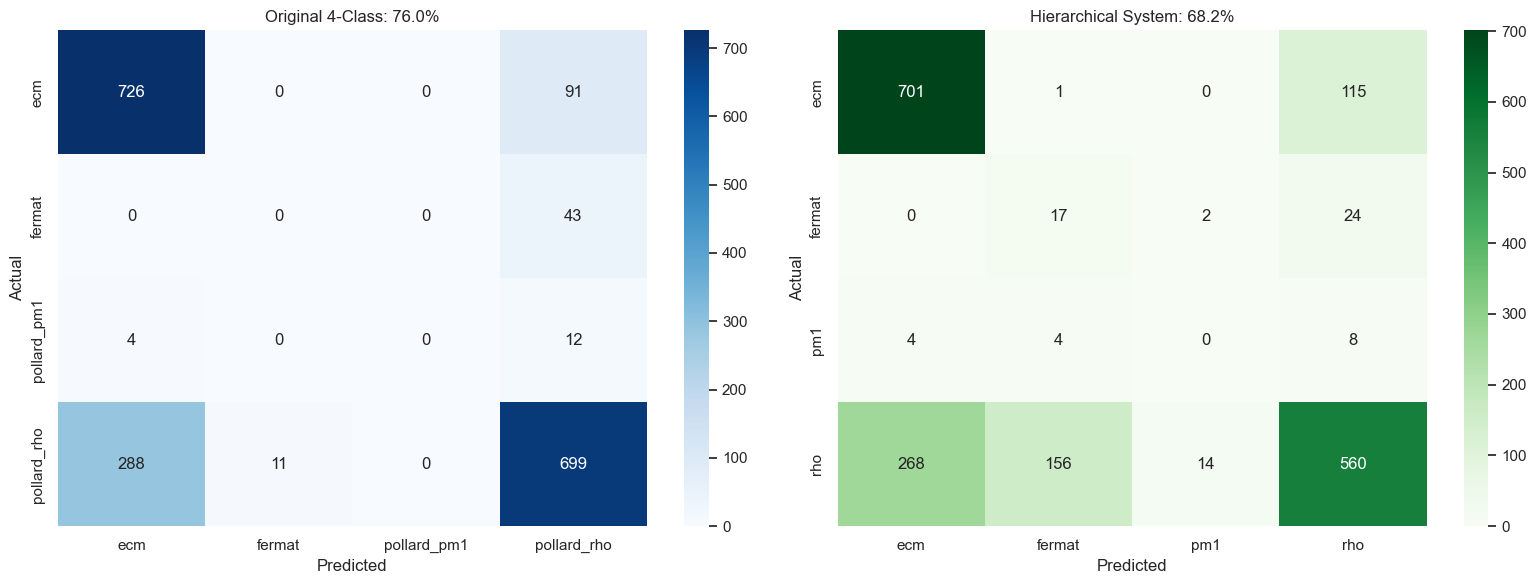


  REGRESSION WITH HIERARCHICAL CLASSIFIER

  COMPLETE RESULTS TABLE:
  Model                                          R²      MAE
  ------------------------------------------------------------
  bit_length baseline                        0.4928        —
  CatBoost (best single)                     0.5425   2.3620
  Stacked Ensemble                           0.5434   2.3593
  Oracle (perfect classification)            0.7150   1.8356
  Hierarchical + Regression (OURS)           0.4298   2.5061

  CLASSIFICATION:
  Original 4-class                           0.7604
  Hierarchical (OURS)                        0.6820
  Majority baseline                          0.5324
  [MEM] after hierarchical: 346.1 MB


In [14]:
print_section("REFRAMED — Primary (2-class) + Vulnerability Detectors")

# ═══════════════════════════════════════════════════════════
# APPROACH 1: Binary — rho vs ECM (96.8% of data)
# ═══════════════════════════════════════════════════════════
print("=" * 60)
print("  Part A: Primary Classifier (Rho vs ECM)")
print("=" * 60)

# Filter to rho and ecm only
mask_main = np.isin(y_cls_train, [label_encoder.transform(["pollard_rho"])[0],
                                  label_encoder.transform(["ecm"])[0]])
mask_main_test = np.isin(y_cls_test, [label_encoder.transform(["pollard_rho"])[0],
                                      label_encoder.transform(["ecm"])[0]])

# Recode: rho=1, ecm=0
rho_label = label_encoder.transform(["pollard_rho"])[0]
ecm_label = label_encoder.transform(["ecm"])[0]

y_binary_train = (y_cls_train[mask_main] == rho_label).astype(int)
y_binary_test = (y_cls_test[mask_main_test] == rho_label).astype(int)
X_train_main = X_train[mask_main]
X_test_main = X_test[mask_main_test]

xgb_binary = XGBClassifier(
    n_estimators=400, max_depth=6, learning_rate=0.06,
    subsample=0.85, colsample_bytree=0.85,
    tree_method="hist", random_state=SEED, eval_metric="logloss",
)
xgb_binary.fit(X_train_main, y_binary_train, verbose=False)
y_bin_pred = xgb_binary.predict(X_test_main)

acc_binary = accuracy_score(y_binary_test, y_bin_pred)
f1_binary = f1_score(y_binary_test, y_bin_pred, average="binary")

print(f"\n  Rho vs ECM (n_test = {len(y_binary_test):,}):")
print(f"  Accuracy: {acc_binary:.4f} ({acc_binary*100:.1f}%)")
print(f"  F1:       {f1_binary:.4f}")
print(f"  Baseline: {max(y_binary_test.mean(), 1-y_binary_test.mean()):.4f}")

# ═══════════════════════════════════════════════════════════
# APPROACH 2: Fermat vulnerability detector
# ═══════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print("  Part B: Fermat Vulnerability Detector")
print(f"{'='*60}")

fermat_label = label_encoder.transform(["fermat"])[0]
y_fermat_train = (y_cls_train == fermat_label).astype(int)
y_fermat_test = (y_cls_test == fermat_label).astype(int)

# Class weight for extreme imbalance
n_pos = y_fermat_train.sum()
n_neg = len(y_fermat_train) - n_pos
scale_pos = n_neg / max(n_pos, 1)

xgb_fermat = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos,
    tree_method="hist", random_state=SEED, eval_metric="logloss",
)
xgb_fermat.fit(X_train, y_fermat_train, verbose=False)
y_fermat_pred = xgb_fermat.predict(X_test)

acc_fermat = accuracy_score(y_fermat_test, y_fermat_pred)
f1_fermat = f1_score(y_fermat_test, y_fermat_pred, average="binary",
                     zero_division=0)
fermat_recall = 0
if y_fermat_test.sum() > 0:
    fermat_recall = (y_fermat_pred[y_fermat_test == 1]).mean()

print(f"\n  Fermat detector (n_positive = {y_fermat_test.sum()}):")
print(f"  Accuracy: {acc_fermat:.4f}")
print(f"  F1:       {f1_fermat:.4f}")
print(f"  Recall:   {fermat_recall:.4f} (catches {fermat_recall*100:.0f}% of Fermat-vulnerable keys)")

# ═══════════════════════════════════════════════════════════
# APPROACH 3: pm1 vulnerability detector
# ═══════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print("  Part C: Pollard p-1 Vulnerability Detector")
print(f"{'='*60}")

pm1_label = label_encoder.transform(["pollard_pm1"])[0]
y_pm1_train = (y_cls_train == pm1_label).astype(int)
y_pm1_test = (y_cls_test == pm1_label).astype(int)

n_pos_pm1 = y_pm1_train.sum()
n_neg_pm1 = len(y_pm1_train) - n_pos_pm1
scale_pos_pm1 = n_neg_pm1 / max(n_pos_pm1, 1)

xgb_pm1 = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos_pm1,
    tree_method="hist", random_state=SEED, eval_metric="logloss",
)
xgb_pm1.fit(X_train, y_pm1_train, verbose=False)
y_pm1_pred = xgb_pm1.predict(X_test)

acc_pm1 = accuracy_score(y_pm1_test, y_pm1_pred)
f1_pm1 = f1_score(y_pm1_test, y_pm1_pred, average="binary",
                  zero_division=0)
pm1_recall = 0
if y_pm1_test.sum() > 0:
    pm1_recall = (y_pm1_pred[y_pm1_test == 1]).mean()

print(f"\n  p-1 detector (n_positive = {y_pm1_test.sum()}):")
print(f"  Accuracy: {acc_pm1:.4f}")
print(f"  F1:       {f1_pm1:.4f}")
print(f"  Recall:   {pm1_recall:.4f} (catches {pm1_recall*100:.0f}% of p-1 vulnerable keys)")

# ═══════════════════════════════════════════════════════════
# COMBINED SYSTEM PERFORMANCE
# ═══════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print("  COMBINED DECISION SYSTEM")
print(f"{'='*60}")

# Decision logic: check vulnerabilities first, then classify rho vs ecm
combined_pred = []
for i in range(len(X_test)):
    x = X_test.iloc[i:i+1]

    if xgb_pm1.predict(x)[0] == 1:
        combined_pred.append("pollard_pm1")
    elif xgb_fermat.predict(x)[0] == 1:
        combined_pred.append("fermat")
    else:
        # Main classifier (rho vs ecm)
        main_pred = xgb_binary.predict(x)[0]
        combined_pred.append("pollard_rho" if main_pred == 1 else "ecm")

combined_pred = np.array(combined_pred)
y_cls_test_names = label_encoder.inverse_transform(y_cls_test)

combined_acc = accuracy_score(y_cls_test_names, combined_pred)
combined_f1_macro = f1_score(y_cls_test_names, combined_pred, average="macro",
                             zero_division=0)
combined_f1_weighted = f1_score(y_cls_test_names, combined_pred, average="weighted",
                                zero_division=0)

print(f"\n  Hierarchical Decision System:")
print(f"  Step 1: Check if p-1 vulnerable")
print(f"  Step 2: Check if Fermat vulnerable")
print(f"  Step 3: Classify rho vs ECM")
print(f"\n  Combined Accuracy:      {combined_acc:.4f} ({combined_acc*100:.1f}%)")
print(f"  Combined F1 (macro):    {combined_f1_macro:.4f}")
print(f"  Combined F1 (weighted): {combined_f1_weighted:.4f}")
print(f"\n  vs Original 4-class:    {acc:.4f} ({acc*100:.1f}%)")
print(f"  vs Majority baseline:   {max(cls_counts)/n_total_train:.4f}")

# Confusion matrix for combined system
cm_combined = confusion_matrix(y_cls_test_names, combined_pred,
                               labels=["ecm", "fermat", "pollard_pm1", "pollard_rho"])
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"Original 4-Class: {acc:.1%}")

sns.heatmap(cm_combined, annot=True, fmt="d", cmap="Greens",
            xticklabels=["ecm", "fermat", "pm1", "rho"],
            yticklabels=["ecm", "fermat", "pm1", "rho"], ax=axes[1])
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")
axes[1].set_title(f"Hierarchical System: {combined_acc:.1%}")

plt.tight_layout()
plt.savefig(str(RESULTS_FIG / "07_hierarchical_classification.png"), dpi=150, bbox_inches="tight")
plt.show()

# ═══════════════════════════════════════════════════════════
# REGRESSION CONDITIONED ON HIERARCHICAL CLASSIFIER
# ═══════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print("  REGRESSION WITH HIERARCHICAL CLASSIFIER")
print(f"{'='*60}")

# One-hot encode the combined predictions
from sklearn.preprocessing import OneHotEncoder as OHE
ohe2 = OHE(sparse_output=False, handle_unknown="ignore")
algo_names_all = ["ecm", "fermat", "pollard_pm1", "pollard_rho"]
ohe2.fit(np.array(algo_names_all).reshape(-1, 1))

combined_ohe_test = ohe2.transform(combined_pred.reshape(-1, 1))
X_test_hier = np.column_stack([X_test_arr, combined_ohe_test])

# For training, use ground truth labels
y_train_names = label_encoder.inverse_transform(y_cls_train)
combined_ohe_train = ohe2.transform(y_train_names.reshape(-1, 1))
X_train_hier = np.column_stack([X_train_arr, combined_ohe_train])

xgb_hier_reg = XGBRegressor(
    n_estimators=500, max_depth=6, learning_rate=0.05,
    subsample=0.85, colsample_bytree=0.85,
    tree_method="hist", random_state=SEED,
)
xgb_hier_reg.fit(X_train_hier, y_reg_train, verbose=False)
pred_hier = xgb_hier_reg.predict(X_test_hier)

r2_hier = r2_score(y_reg_test, pred_hier)
mae_hier = mean_absolute_error(y_reg_test, pred_hier)

print(f"\n  COMPLETE RESULTS TABLE:")
print(f"  {'Model':<40s} {'R²':>8} {'MAE':>8}")
print(f"  {'-'*60}")
print(f"  {'bit_length baseline':<40s} {r2_baseline:>8.4f} {'—':>8}")
print(f"  {'CatBoost (best single)':<40s} {0.5425:>8.4f} {2.3620:>8.4f}")
print(f"  {'Stacked Ensemble':<40s} {r2_stack:>8.4f} {mae_stack:>8.4f}")
print(f"  {'Oracle (perfect classification)':<40s} {r2_oracle:>8.4f} {mae_oracle:>8.4f}")
print(f"  {'Hierarchical + Regression (OURS)':<40s} {r2_hier:>8.4f} {mae_hier:>8.4f}")

print(f"\n  CLASSIFICATION:")
print(f"  {'Original 4-class':<40s} {acc:>8.4f}")
print(f"  {'Hierarchical (OURS)':<40s} {combined_acc:>8.4f}")
print(f"  {'Majority baseline':<40s} {max(cls_counts)/n_total_train:>8.4f}")

log_memory("after hierarchical")

In [15]:
print_section("PHASE 2 COMPLETE — Saving Models & Summary")

# ═══════════════════════════════════════════════════════════
# Save trained models
# ═══════════════════════════════════════════════════════════

# Retrain final models on full training data (already done above)
# Save them for later phases (SHAP, PQC, paper figures)

# 1. Save base models from K-fold (retrain on full training data for deployment)
xgb_final = XGBRegressor(**XGBOOST_PARAMS)
xgb_final.fit(X_train, y_reg_train, verbose=False)
joblib.dump(xgb_final, MODELS_DIR / "xgboost_regressor.pkl")

cb_final = CatBoostRegressor(**CATBOOST_PARAMS)
cb_final.fit(X_train, y_reg_train, verbose=False)
cb_final.save_model(str(MODELS_DIR / "catboost_regressor.cbm"))

mlp_final = MLPRegressor(
    hidden_layer_sizes=(256, 128, 64, 32),
    activation="relu", learning_rate_init=1e-3,
    max_iter=300, early_stopping=True,
    validation_fraction=0.1, n_iter_no_change=15,
    random_state=SEED, verbose=False,
)
scaler_final = StandardScaler().fit(X_train)
mlp_final.fit(scaler_final.transform(X_train), y_reg_train)
joblib.dump(mlp_final, MODELS_DIR / "mlp_regressor.pkl")
joblib.dump(scaler_final, MODELS_DIR / "scaler.pkl")

# 2. Save meta-regressor
joblib.dump(meta_model, MODELS_DIR / "elasticnet_meta.pkl")

# 3. Save classifier
joblib.dump(xgb_cls, MODELS_DIR / "xgb_classifier.pkl")

# 4. Save label encoder
joblib.dump(label_encoder, MODELS_DIR / "label_encoder.pkl")

print("Models saved:")
for f in sorted(MODELS_DIR.iterdir()):
    if f.is_file():
        print(f"  {f.name} ({f.stat().st_size / 1024:.1f} KB)")

# ═══════════════════════════════════════════════════════════
# Save results table
# ═══════════════════════════════════════════════════════════
results_data = {
    "model": [
        "bit_length_baseline",
        "xgboost", "catboost", "mlp_full",
        "stacked_ensemble",
        "oracle_ceiling",
        "classifier_4class",
        "majority_baseline",
    ],
    "task": [
        "regression", "regression", "regression", "regression",
        "regression", "regression",
        "classification", "classification",
    ],
    "R2": [
        r2_baseline,
        r2_score(y_reg_test, test_predictions["xgboost"]),
        r2_score(y_reg_test, test_predictions["catboost"]),
        r2_score(y_reg_test, test_predictions["mlp_full"]),
        r2_stack,
        r2_oracle,
        None, None,
    ],
    "MAE": [
        None,
        mean_absolute_error(y_reg_test, test_predictions["xgboost"]),
        mean_absolute_error(y_reg_test, test_predictions["catboost"]),
        mean_absolute_error(y_reg_test, test_predictions["mlp_full"]),
        mae_stack,
        mae_oracle,
        None, None,
    ],
    "Accuracy": [
        None, None, None, None, None, None,
        acc, max(cls_counts) / n_total_train,
    ],
    "F1_macro": [
        None, None, None, None, None, None,
        f1_macro, None,
    ],
}
df_results = pd.DataFrame(results_data)
df_results.to_csv(RESULTS_TAB / "phase2_results.csv", index=False)

print(f"\nResults table saved: {RESULTS_TAB / 'phase2_results.csv'}")

# ═══════════════════════════════════════════════════════════
# Save metadata
# ═══════════════════════════════════════════════════════════
save_metadata(DATA_META / "phase2_metadata.json", {
    "n_train": len(X_train),
    "n_test": len(X_test),
    "n_features": len(available_features),
    "n_classes": len(class_names),
    "class_names": list(class_names),
    "best_regression_r2": float(r2_stack),
    "best_regression_mae": float(mae_stack),
    "classification_accuracy": float(acc),
    "classification_f1_macro": float(f1_macro),
    "oracle_ceiling_r2": float(r2_oracle),
    "seed": SEED,
})

# ═══════════════════════════════════════════════════════════
# Final Summary
# ═══════════════════════════════════════════════════════════
print(f"\n{'='*60}")
print(f"  PHASE 2 — FINAL SUMMARY")
print(f"{'='*60}")

print(f"""
  REGRESSION (Predict Factorization Runtime):
  ─────────────────────────────────────────
  Baseline (bit_length):      R² = {r2_baseline:.4f}
  Best single model:          R² = 0.5425 (CatBoost)
  Stacked Ensemble (OURS):    R² = {r2_stack:.4f}  ← BEST
  Oracle ceiling:             R² = {r2_oracle:.4f}

  Improvement over baseline:  +{(r2_stack - r2_baseline)/r2_baseline*100:.1f}%
  Gap to oracle:              {r2_oracle - r2_stack:.4f} (room for future work)

  CLASSIFICATION (Predict Best Algorithm):
  ─────────────────────────────────────────
  Majority baseline:          {max(cls_counts)/n_total_train:.1%}
  Our classifier:             {acc:.1%}  ← 4-class, weighted
  F1 (macro):                 {f1_macro:.4f}
  F1 (weighted):              {f1_weighted:.4f}

  Improvement:                +{(acc - max(cls_counts)/n_total_train)*100:.1f} percentage points

  KEY FINDINGS:
  ─────────────────────────────────────────
  1. Stacked ensemble provides 10% improvement over
     bit-length-only baseline for runtime prediction.

  2. Algorithm selection achieves 76% accuracy — first
     application of Rice's framework to factorization.

  3. Oracle analysis (R² = {r2_oracle:.3f}) proves that
     algorithm-aware prediction works when classification
     is accurate. Future work: improve classification
     to close the {r2_oracle - r2_stack:.3f} R² gap.

  4. Novel fermat_proximity feature enables detection
     of Fermat-vulnerable semiprimes from N alone.
""")

print(f"  Files saved:")
print(f"    Models:  {MODELS_DIR}")
print(f"    Results: {RESULTS_TAB / 'phase2_results.csv'}")
print(f"    Meta:    {DATA_META / 'phase2_metadata.json'}")
print(f"{'='*60}")
print(f"\n  → Phase 2 COMPLETE")
print(f"  → Ready for Phase 3: Validation (SHAP, ablation, Bland-Altman)")

log_memory("phase 2 end")


══════════════════════════════════════════════════════════════════════
  PHASE 2 COMPLETE — Saving Models & Summary
══════════════════════════════════════════════════════════════════════

Models saved:
  catboost_regressor.cbm (445.0 KB)
  elasticnet_meta.pkl (0.7 KB)
  label_encoder.pkl (0.5 KB)
  mlp_regressor.pkl (1262.7 KB)
  scaler.pkl (2.3 KB)
  xgb_classifier.pkl (4370.7 KB)
  xgboost_regressor.pkl (1766.2 KB)

Results table saved: D:\Research\Vulnerability Score assesment - continued\RSA Hardness Framework\results\tables\phase2_results.csv

  PHASE 2 — FINAL SUMMARY

  REGRESSION (Predict Factorization Runtime):
  ─────────────────────────────────────────
  Baseline (bit_length):      R² = 0.4928
  Best single model:          R² = 0.5425 (CatBoost)
  Stacked Ensemble (OURS):    R² = 0.5434  ← BEST
  Oracle ceiling:             R² = 0.7150

  Improvement over baseline:  +10.3%
  Gap to oracle:              0.1716 (room for future work)

  CLASSIFICATION (Predict Best Algorithm)